# HW1 : Introduction and Learnability — PAC vs Agnostic PAC
**Yasmine MEJRISSI — M2 IMDS (UHA) — Professeur : Ali Ismail FAWAZ**

Dans ce devoir, je compare deux situations d'apprentissage avec un classifieur très simple : un seuil sur [0, 1].
D'abord, les étiquettes sont parfaites (cadre réalisable, PAC). Ensuite, j'ajoute du bruit sur les étiquettes (cadre agnostique).
L'idée est de voir concrètement ce que ça change pour l'erreur d'entraînement, l'erreur sur de nouvelles données, et la quantité de données nécessaire pour bien apprendre.

J'utilise seulement numpy, pandas et matplotlib, et pas de librairies de machine learning comme demandé. L'algorithme d'apprentissage (ERM) est codé à la main.

In [75]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


sizes=[5, 10, 20, 50, 100, 200]

## 1. Data Generation

Je tire des points x au hasard, de façon uniforme, entre 0 et 1.
Chaque point reçoit une étiquette selon un seuil caché θ = 0,4 : y = 1 si x > 0,4, sinon y = 0.
Je crée un jeu de données pour chaque taille m = 5, 10, 20, 50, 100 et 200.

Ici, il n'y a pas de bruit : le seuil θ classe parfaitement tous les points. C'est le cadre réalisable.

In [77]:
theta=0.4

liste_x={}
liste_y={}
for m in sizes:
  x=np.random.uniform(0, 1, size=m)
  y=(x>theta).astype(int)
  liste_x[m]=x
  liste_y[m]=y


print(liste_x[20], liste_y[20])

[0.32345688 0.13655705 0.08342942 0.10506043 0.61296671 0.58337694
 0.84878845 0.77951983 0.51303863 0.45522682 0.24771934 0.85521635
 0.79195501 0.59088402 0.52780852 0.31039221 0.97020074 0.41794981
 0.5530193  0.83680252] [0 0 0 0 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1]


In [78]:
df_x={}
for m in liste_x.keys():
  df_x[m]=pd.DataFrame({"x": liste_x[m], "y":liste_y[m]})

print(df_x[10])

          x  y
0  0.216503  0
1  0.945273  1
2  0.366271  0
3  0.519355  1
4  0.448439  1
5  0.286392  0
6  0.969488  1
7  0.902769  1
8  0.874835  1
9  0.696575  1


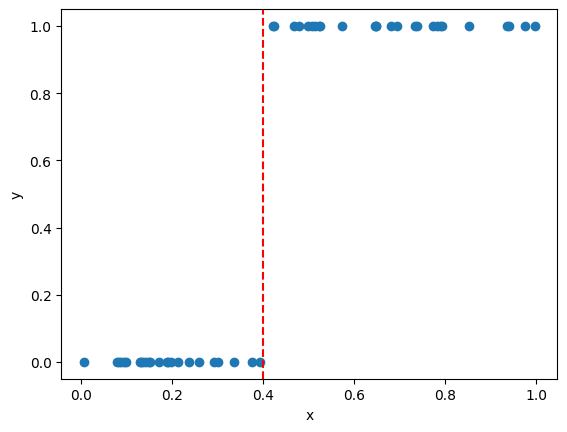

In [79]:
x=liste_x[50]
y=liste_y[50]

plt.figure()
plt.scatter(x, y)
plt.axvline(theta, color="red", linestyle="--")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Les points étiquetés 0 sont tous à gauche de la ligne rouge (θ = 0,4) et les points étiquetés 1 tous à droite : le seuil sépare parfaitement les deux classes.

## 2. Implementation of ERM

In [81]:
def empirical_risk(x_data, y_true, threshold_candidate):
  predictions=(x_data>threshold_candidate).astype(int)
  return (predictions != y_true).astype(float).mean()

def erm(x ,y):
  theta_candidats=np.linspace(0,1,1000)
  risk=[empirical_risk(x, y, t) for t in theta_candidats]
  best_theta=theta_candidats[np.argmin(risk)]
  return best_theta



L'ERM (minimisation du risque empirique) choisit, parmi tous les seuils possibles, celui qui fait le moins d'erreurs sur les données d'entraînement.

J'ai écrit deux fonctions :
- `empirical_risk` calcule la proportion d'erreurs d'un seuil t donné ;
- `erm` teste une grille de 1000 seuils régulièrement espacés entre 0 et 1 et garde celui qui a la plus petite erreur.

Le pas de la grille est d'environ 0,001, ce qui est très petit devant le ε que j'utilise ensuite (0,05).
Quand plusieurs seuils font aussi bien, `np.argmin` garde le premier, donc le plus petit. Dans le cadre sans bruit, le seuil appris est donc toujours un peu en dessous de θ.

## 3. Performance Evaluation

Pour chaque taille m, j'entraîne l'ERM puis je calcule deux erreurs :
- l'erreur empirique, sur les points d'entraînement ;
- l'erreur vraie, que j'estime sur un grand jeu de test indépendant (100 000 points jamais vus par l'algorithme).

Je ne peux pas mesurer l'erreur vraie sur l'entraînement, car l'ERM a justement choisi le seuil pour bien réussir sur ces points-là : ce serait trop optimiste.

In [82]:
x_test=np.random.uniform(0, 1, size=100000)
y_test=(x_test>theta).astype(int)

for m in sizes:
  t=erm(liste_x[m], liste_y[m])
  err_emp=empirical_risk(liste_x[m], liste_y[m], t)
  err_vraie=empirical_risk(x_test, y_test, t)
  print("m = ", m, ", estimation de theta : ", t, ", erreur empirique : ", err_emp, ", erreur vraie : ", err_vraie)
  #print("Meilleure hypothèse h_t : ", best_theta, "\n", " erreur empirique : ", best_theta)


m =  5 , estimation de theta :  0.3353353353353353 , erreur empirique :  0.0 , erreur vraie :  0.06501
m =  10 , estimation de theta :  0.3663663663663664 , erreur empirique :  0.0 , erreur vraie :  0.03323
m =  20 , estimation de theta :  0.32432432432432434 , erreur empirique :  0.0 , erreur vraie :  0.07649
m =  50 , estimation de theta :  0.3923923923923924 , erreur empirique :  0.0 , erreur vraie :  0.00776
m =  100 , estimation de theta :  0.40040040040040037 , erreur empirique :  0.0 , erreur vraie :  0.00043
m =  200 , estimation de theta :  0.3993993993993994 , erreur empirique :  0.0 , erreur vraie :  0.00056


- L'erreur empirique vaut 0 pour tous les m : sans bruit, il existe toujours un seuil qui classe parfaitement les points d'entraînement, et l'ERM le trouve.
- L'erreur vraie, elle, n'est pas nulle : elle correspond à l'écart entre le seuil appris et θ. Elle diminue globalement quand m augmente.
- Une erreur empirique nulle ne garantit donc pas une erreur vraie nulle, surtout quand on a peu de données.
- La décroissance n'est pas parfaitement régulière, car je n'ai fait qu'un seul tirage par taille. C'est pour ça que je répète l'expérience dans la partie suivante.

## 4. Experimental verification of PAC Learning

Un seul tirage par taille dépend beaucoup du hasard. Je répète donc l'expérience 1000 fois pour chaque m, avec à chaque fois un nouveau jeu d'entraînement.

Je fixe ε = 0,05 et je compte un « échec » quand l'erreur vraie dépasse ε.
La proportion d'échecs sur les 1000 essais me donne une estimation de P(L(h) > ε).
Je compare ensuite cette courbe à la formule théorique (1 − ε)^m.

In [83]:
n=1000
eps=0.05

proba_echec=[]

for m in sizes:
  nb_echecs=0
  for r in range(n):
    x_train=np.random.uniform(0,1,size=m)
    y_train=(x_train>theta).astype(int)
    t=erm(x_train, y_train)
    err_vraie=empirical_risk(x_test, y_test, t)
    if err_vraie>eps:
      nb_echecs+=1
  proba_echec.append(nb_echecs/n)

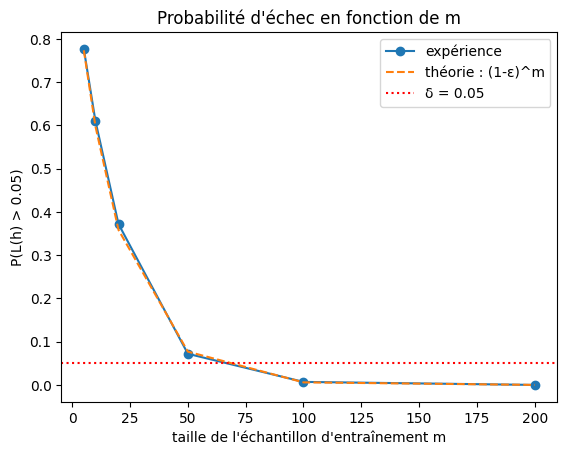

[0.777, 0.611, 0.372, 0.072, 0.007, 0.0]


In [84]:
plt.plot(sizes, proba_echec, "o-", label="expérience")
plt.plot(sizes, (1 - eps) ** np.array(sizes), "--", label="théorie : (1-ε)^m")
plt.axhline(0.05, color="red", linestyle=":", label="δ = 0.05")
plt.xlabel("taille de l'échantillon d'entraînement m")
plt.ylabel(f"P(L(h) > {eps})")
plt.title("Probabilité d'échec en fonction de m")
plt.legend()
plt.show()
print(proba_echec)

La probabilité d'échec diminue très vite quand m augmente : environ 78 % pour m = 5, 37 % pour m = 20, puis presque 0 à partir de m = 100.
Les valeurs obtenues sont très proches de la courbe théorique (1 − ε)^m. L'ERM se trompe de plus de ε seulement si aucun point d'entraînement ne tombe dans la bande [θ − ε, θ], et ça devient très improbable quand on a beaucoup de données.
La probabilité passe sous δ = 0,05 entre m = 50 et m = 100. C'est le principe du PAC learning : avec assez d'exemples, on est presque sûr d'obtenir une bonne hypothèse.

## 5. From PAC to Agnostic PAC

Je refais les mêmes expériences en ajoutant du bruit : chaque étiquette est inversée avec une probabilité η = 0,1.
J'applique le bruit aux données d'entraînement et au jeu de test.

Avec ce bruit, même le meilleur seuil (t = θ) se trompe sur environ 10 % des points. Garder la règle « échec si L(h) > ε » donnerait donc 100 % d'échecs, quel que soit m.
Je compare plutôt l'erreur au meilleur classifieur possible : un échec devient L(h) > η + ε.

In [85]:
eta=0.1

def generate_noisy(m):
  x=np.random.uniform(0, 1, size=m)
  y=(x>theta).astype(int)
  for i in range(m):
    if np.random.rand()<eta:
      y[i]=1-y[i]
  return x, y

x_test_n, y_test_n=generate_noisy(50000)

for m in sizes:
  x_train, y_train=generate_noisy(m)
  theta_learned=erm(x_train, y_train)
  err_emp=empirical_risk(x_train, y_train, theta_learned)
  err_vraie=empirical_risk(x_test_n, y_test_n, theta_learned)
  print("m = ", m, ", estimation de theta : ", theta_learned, ", erreur empirique : ", err_emp, ", erreur vraie : ", err_vraie)



m =  5 , estimation de theta :  0.17417417417417416 , erreur empirique :  0.0 , erreur vraie :  0.27992
m =  10 , estimation de theta :  0.3793793793793794 , erreur empirique :  0.0 , erreur vraie :  0.1184
m =  20 , estimation de theta :  0.35735735735735735 , erreur empirique :  0.1 , erreur vraie :  0.13614
m =  50 , estimation de theta :  0.39039039039039036 , erreur empirique :  0.06 , erreur vraie :  0.10878
m =  100 , estimation de theta :  0.3813813813813814 , erreur empirique :  0.11 , erreur vraie :  0.11658
m =  200 , estimation de theta :  0.39039039039039036 , erreur empirique :  0.075 , erreur vraie :  0.10878


Cette fois, l'erreur empirique n'est plus toujours nulle : elle vaut encore 0 pour m = 5 et m = 10, simplement par chance, mais plus à partir de m = 20, car certains points mal étiquetés ne peuvent plus être bien classés par un seuil.
L'erreur vraie reste autour ou au-dessus de 0,1 pour tous les m. L'erreur empirique est souvent plus petite que l'erreur vraie : l'ERM s'adapte aussi au bruit de l'échantillon, donc l'erreur d'entraînement est trop optimiste.

In [86]:
n=1000
eps=0.05
eta=0.1

proba_agnostic=[]
err_emp_moy=[]
err_vraie_moy=[]

for m in sizes:
  nb_echecs=0
  liste_err_emp=[]
  liste_err_vraie=[]
  for i in range(n):
    x_train, y_train=generate_noisy(m)
    theta_learned=erm(x_train, y_train)
    erreur_emp=empirical_risk(x_train, y_train, theta_learned)
    erreur_vraie=empirical_risk(x_test_n, y_test_n, theta_learned)
    liste_err_emp.append(erreur_emp)
    liste_err_vraie.append(erreur_vraie)
    if erreur_vraie>eta+eps:
      nb_echecs+=1
  proba_agnostic.append(nb_echecs/n)
  err_emp_moy.append(np.mean(liste_err_emp))
  err_vraie_moy.append(np.mean(liste_err_vraie))

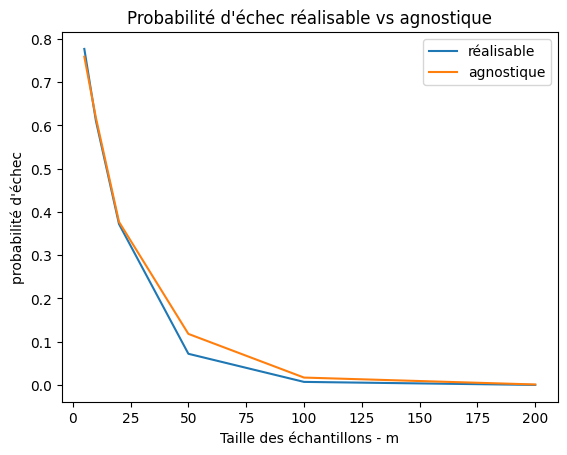

In [87]:
plt.plot(sizes, proba_echec, label="réalisable")
plt.plot(sizes, proba_agnostic, label="agnostique")
plt.title("Probabilité d'échec réalisable vs agnostique")
plt.xlabel("Taille des échantillons - m")
plt.ylabel("probabilité d'échec")
plt.legend()
plt.show()

Les deux courbes décroissent vers 0. La courbe agnostique est un peu au-dessus de la courbe réalisable, surtout autour de m = 50 : avec du bruit, il faut un peu plus de données pour la même fiabilité.

In [88]:
print("eta =", eta, ",  epsilon =", eps)
print("proba_agnostic =", proba_agnostic)

eta = 0.1 ,  epsilon = 0.05
proba_agnostic = [0.759, 0.618, 0.377, 0.118, 0.017, 0.001]


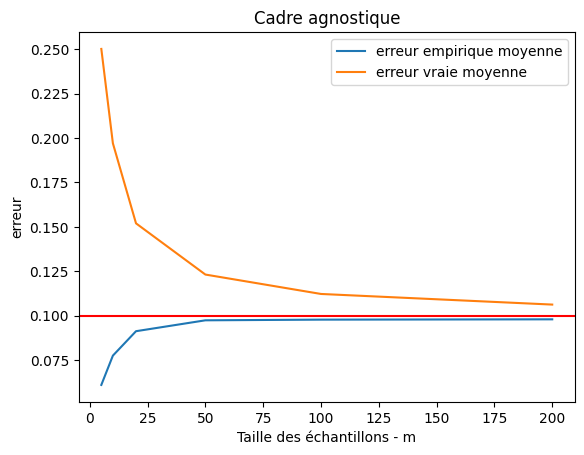

In [89]:
plt.plot(sizes, err_emp_moy, label="erreur empirique moyenne")
plt.plot(sizes, err_vraie_moy, label="erreur vraie moyenne")
plt.axhline(eta, color="red")
plt.xlabel("Taille des échantillons - m")
plt.ylabel("erreur")
plt.title("Cadre agnostique")
plt.legend()
plt.show()

**L'erreur empirique peut-elle encore atteindre 0 ?** Non, sauf parfois par hasard quand m est très petit. Certains points sont mal étiquetés, donc aucun seuil ne peut tous les classer correctement.

**Augmenter m améliore-t-il encore la généralisation ?** Oui, mais l'erreur vraie tend vers 0,1 et non plus vers 0, car même le meilleur seuil se trompe sur les points bruités. Plus de données permettent de se rapprocher du meilleur classifieur possible, pas de faire mieux que le bruit.

**Lien avec PAC et Agnostic PAC :** dans le cadre PAC, on vise une erreur proche de 0 (L(h) ≤ ε). Dans le cadre Agnostic PAC, on vise une erreur proche de la meilleure de la classe (L(h) ≤ min L + ε). C'est exactement pour ça que j'ai redéfini l'échec comme L(h) > η + ε.

## Conclusion

Sans bruit, l'ERM trouve toujours un seuil sans erreur sur l'entraînement, et son erreur vraie tend vers 0 quand m augmente.
Avec du bruit, l'erreur d'entraînement ne descend plus à 0 et l'erreur vraie tend vers η, pas vers 0.
Dans les deux cas, avoir plus de données rend l'apprentissage plus fiable, mais avec du bruit, il en faut un peu plus.

Ce travail nous a permis de voir que le PAC vise une erreur presque nulle, tandis que l'Agnostic PAC vise une erreur proche de la meilleure possible.